In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("IT_Service_Availability_and_Downtime_Analysis_Messy part 6.csv")

In [3]:
df.head(10)

,Service ID,Service Name,Timestamp,Availability Status,Downtime Duration,Incident Type,Maintenance Window,Response Time
0,SRV-009,Web Application,2026-07-21 18:15:00,AVAILABLE,0.0,none,NO,10.97
1,SRV-009,Web Application,2026-01-19 22:50:00,Available,0.0,NONE,NO,18.17
2,SRV-008,Inventory System,2026-07-12 07:14:00,AVAILABLE,0.0,NONE,NO,14.21
3,SRV-007,HR Management System,2026-07-22 13:35:00,AVAILABLE,NaN,NONE,NO,26.34
4,SRV-003,Customer Portal,2026-06-21 17:30:00,MAINTENANCE,116.0,NETWORK,YES,NaN
5,SRV-004,Database Server,2026-02-11 00:36:00,DOWN,360.0,DATABASE,NO,NaN
6,SRV-004,Database Server,2026-01-19 18:20:00,AVAILABLE,NaN,NONE,YES,12.26
7,SRV-004,Database Server,2026-01-04 06:01:00,MAINTENANCE,153.0,POWER,YES,81.48
8,SRV-002,Payment Gateway,2026-06-26 02:18:00,DOWN,319.0,POWER,NO,15.75
9,SRV-007,HR Management System,2026-02-20 06:27:00,DEGRADED,85.0,NETWORK,NO,17.54


In [4]:
df.shape

(1218, 8)

In [5]:
df.size

9744

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Service ID           1187 non-null   object
 1   Service Name         1173 non-null   object
 2   Timestamp            1196 non-null   object
 3   Availability Status  1164 non-null   object
 4   Downtime Duration    1073 non-null   object
 5   Incident Type        1131 non-null   object
 6   Maintenance Window   1151 non-null   object
 7   Response Time        1086 non-null   object
dtypes: object(8)
memory usage: 76.3+ KB


In [7]:
df1 = pd.DataFrame({
    "data type":df.dtypes,
    "Total Missing Value": df.isna().sum().sum(),
    "Missing Value in Each Column": df.isna().sum(),
    "missing percentage":(df.isna().sum()/len(df))*100,
    "Non Missing Value": df.notna().sum(),
    "Duplicate Value": df.duplicated().sum(),
    "unique Value": df.nunique()
})
df1

,data type,Total Missing Value,Missing Value in Each Column,missing percentage,Non Missing Value,Duplicate Value,unique Value
Service ID,object,583,31,2.545156,1187,18,10
Service Name,object,583,45,3.694581,1173,18,10
Timestamp,object,583,22,1.806240,1196,18,1177
Availability Status,object,583,54,4.433498,1164,18,16
Downtime Duration,object,583,145,11.904762,1073,18,218
Incident Type,object,583,87,7.142857,1131,18,14
Maintenance Window,object,583,67,5.500821,1151,18,8
Response Time,object,583,132,10.837438,1086,18,960


In [29]:
df.describe()

,Timestamp
count,1179
mean,2026-04-19 12:57:44.681933824
min,2026-01-01 01:36:00
25%,2026-02-23 05:02:00
50%,2026-04-20 23:56:00
75%,2026-06-13 03:52:00
max,2026-12-06 08:10:00


In [8]:
df[df.duplicated(keep=False)]

,Service ID,Service Name,Timestamp,Availability Status,Downtime Duration,Incident Type,Maintenance Window,Response Time
10,SRV-002,Payment Gateway,2026-06-01 17:50:00,AVAILABLE,0.0,NaN,NO,4.38
20,SRV-008,NaN,NaN,AVAILABLE,0.0,NONE,NO,48.15
50,SRV-007,HR Management System,2026-03-22 08:10:00,AVAILABLE,-1,NONE,NO,NaN
58,SRV-010,Network Monitoring,2026-03-31 15:27:00,AVAILABLE,0.0,NONE,NO,18.18
66,SRV-007,HR Management System,2026-04-20 09:49:00,AVAILABLE,9.0,NONE,NO,54.85
71,SRV-003,Customer Portal,2026-02-24 07:42:00,OFFLINE,165.0,NETWORK,NO,26.17
79,SRV-007,NaN,2026-01-27 22:19:00,AVAILABLE,0.0,NONE,NaN,11.26
130,SRV-001,Email Service,2026-03-15 13:57:00,DEGRADED,57.0,SECURITY,YES,27.89
146,NaN,Cloud Storage,2026-01-26 04:19:00,DOWN,417.0,NaN,NO,NaN
162,SRV-003,Customer Portal,2026-02-10 10:53:00,DEGRADED,59.0,DATABASE,NO,NaN


In [9]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

# Service id

In [10]:
df["Service ID"].isna().sum()

np.int64(30)

In [11]:
df[df["Service ID"].isna()]

,Service ID,Service Name,Timestamp,Availability Status,Downtime Duration,Incident Type,Maintenance Window,Response Time
11,NaN,Network Monitoring,2026-02-04 17:17:00,DEGRADED,NaN,NETWORK,NO,11.37
31,NaN,Email Service,2026-06-26 16:38:00,AVAILABLE,0.0,NONE,NaN,34.11
33,NaN,Database Server,2026-05-09 06:37:00,AVAILABLE,0.0,none,NO,36.84
141,NaN,Cloud Storage,2026-06-22 19:13:00,MAINTENANCE,139.0,SOFTWARE,YES,12.89
146,NaN,Cloud Storage,2026-01-26 04:19:00,DOWN,417.0,NaN,NO,NaN
233,NaN,Cloud Storage,2026-07-19 00:14:00,AVAILABLE,NaN,NONE,NO,29.37
242,NaN,VPN Service,2026-05-24 00:44:00,AVAILABLE,0.0,NONE,NO,28.74
251,NaN,Customer Portal,2026-01-27 22:35:00,AVAILABLE,0.0,NONE,NO,32.44
254,NaN,Web Application,2026-04-15 03:09:00,AVAILABLE,0.0,NONE,FALSE,55.49
255,NaN,HR Management System,2026-05-04 10:32:00,NaN,132.0,POWER,YES,16.73


In [12]:
df["Service ID"].value_counts()

Service ID
SRV-002    144
SRV-003    136
SRV-010    136
SRV-009    120
SRV-005    115
SRV-008    110
SRV-006    107
SRV-004    105
SRV-001     99
SRV-007     98
Name: count, dtype: int64

In [22]:
print(df[["Service Name", "Service ID"]].head(20))

            Service Name Service ID
0        Web Application    SRV-009
1        Web Application    SRV-009
2       Inventory System    SRV-008
3   HR Management System    SRV-007
4        Customer Portal    SRV-003
5        Database Server    SRV-004
6        Database Server    SRV-004
7        Database Server    SRV-004
8        Payment Gateway    SRV-002
9   HR Management System    SRV-007
10       Payment Gateway    SRV-002
11    Network Monitoring        NaN
12       Payment Gateway    SRV-002
13    Network Monitoring    SRV-010
14      Inventory System    SRV-008
15    Network Monitoring    SRV-010
16      Inventory System    SRV-008
17    Network Monitoring    SRV-010
18       Customer Portal    SRV-003
19      Inventory System    SRV-008


In [23]:
service_map = df.groupby("Service Name")["Service ID"].agg(lambda x: x.mode()[0])
print(service_map)

Service Name
Cloud Storage           SRV-005
Customer Portal         SRV-003
Database Server         SRV-004
Email Service           SRV-001
HR Management System    SRV-007
Inventory System        SRV-008
Network Monitoring      SRV-010
Payment Gateway         SRV-002
Unknown                 SRV-010
VPN Service             SRV-006
Web Application         SRV-009
Name: Service ID, dtype: object


In [24]:
df["Service ID"] = df["Service ID"].fillna(
    df["Service Name"].map(service_map)
)

In [25]:
print("Missing Values:", df["Service ID"].isna().sum())

Missing Values: 0


In [26]:
df["Service ID"].value_counts()

Service ID
SRV-002    147
SRV-010    141
SRV-003    138
SRV-009    122
SRV-005    119
SRV-008    114
SRV-006    111
SRV-004    107
SRV-001    101
SRV-007    100
Name: count, dtype: int64

In [14]:
df.columns

Index(['Service ID', 'Service Name', 'Timestamp', 'Availability Status',
       'Downtime Duration', 'Incident Type', 'Maintenance Window',
       'Response Time'],
      dtype='object')

## service type

In [15]:
df["Service Name"].dtype

dtype('O')

In [16]:
df["Service Name"].unique()

array(['Web Application', 'Inventory System', 'HR Management System',
       'Customer Portal', 'Database Server', 'Payment Gateway',
       'Network Monitoring', nan, 'VPN Service', 'Email Service',
       'Cloud Storage'], dtype=object)

In [17]:
df["Service Name"]=df["Service Name"].fillna("Unknown")

In [18]:
df["Service Name"].unique()

array(['Web Application', 'Inventory System', 'HR Management System',
       'Customer Portal', 'Database Server', 'Payment Gateway',
       'Network Monitoring', 'Unknown', 'VPN Service', 'Email Service',
       'Cloud Storage'], dtype=object)

In [19]:
df["Service Name"]=df["Service Name"].str.strip()

In [20]:
df["Service Name"].unique()

array(['Web Application', 'Inventory System', 'HR Management System',
       'Customer Portal', 'Database Server', 'Payment Gateway',
       'Network Monitoring', 'Unknown', 'VPN Service', 'Email Service',
       'Cloud Storage'], dtype=object)

In [21]:
df["Service Name"].value_counts()

Service Name
Payment Gateway         144
Customer Portal         134
Network Monitoring      131
Web Application         117
Cloud Storage           114
Inventory System        110
VPN Service             110
Database Server         105
HR Management System     97
Email Service            96
Unknown                  42
Name: count, dtype: int64

## Timestamp

In [27]:
df["Timestamp"].dtype

dtype('O')

In [30]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

In [31]:
df["Timestamp"].nunique()

1177

In [32]:
df["Timestamp"].isna().sum()

np.int64(21)

In [33]:
df[df["Timestamp"].isna()]

,Service ID,Service Name,Timestamp,Availability Status,Downtime Duration,Incident Type,Maintenance Window,Response Time
20,SRV-008,Unknown,NaT,AVAILABLE,0.0,NONE,NO,48.15
210,SRV-002,Payment Gateway,NaT,down,187.0,NETWORK,NO,70.71
262,SRV-003,Customer Portal,NaT,AVAILABLE,0.0,NONE,NaN,11.67
263,SRV-001,Email Service,NaT,DOWN,67.0,DATABASE,NO,slow
281,SRV-003,Customer Portal,NaT,AVAILABLE,NaN,NONE,NO,NaN
353,SRV-002,Payment Gateway,NaT,AVAILABLE,0.0,NONE,NO,19.1
385,SRV-006,VPN Service,NaT,DEGRADED,78.0,hardware,NO,NaN
408,SRV-001,Email Service,NaT,AVAILABLE,0.0,NONE,NO,68.48
440,SRV-010,Network Monitoring,NaT,MAINTENANCE,76.0,NETWORK,YES,31.51
559,SRV-001,Email Service,NaT,NaN,0.0,NONE,NO,18.66


In [34]:
(df["Timestamp"].dt.date.value_counts().sort_index().head(30))

Timestamp
2026-01-01     2
2026-01-02     3
2026-01-03     8
2026-01-04     7
2026-01-05     7
2026-01-06     4
2026-01-07     5
2026-01-08     4
2026-01-09     4
2026-01-10     6
2026-01-11     5
2026-01-12     6
2026-01-13     5
2026-01-14     4
2026-01-15     6
2026-01-16     4
2026-01-17     4
2026-01-18     4
2026-01-19     6
2026-01-20     8
2026-01-21     4
2026-01-22     4
2026-01-23     3
2026-01-24     5
2026-01-25     7
2026-01-26    10
2026-01-27     8
2026-01-28     5
2026-01-29     6
2026-01-30     5
Name: count, dtype: int64

In [35]:
df = df.sort_values(by="Timestamp", ascending=True)
df["Timestamp"] = df["Timestamp"].ffill()
df["Timestamp"].isna().sum()

np.int64(0)

In [36]:
df["Timestamp"]

783    2026-01-01 01:36:00
28     2026-01-01 04:59:00
900    2026-01-02 06:21:00
697    2026-01-02 11:53:00
562    2026-01-02 20:22:00
               ...        
893    2026-12-06 08:10:00
950    2026-12-06 08:10:00
1089   2026-12-06 08:10:00
1098   2026-12-06 08:10:00
1193   2026-12-06 08:10:00
Name: Timestamp, Length: 1200, dtype: datetime64[ns]

In [37]:
print(df["Timestamp"].min())
print(df["Timestamp"].max())

2026-01-01 01:36:00
2026-12-06 08:10:00


In [39]:
print(df["Timestamp"].dt.date.nunique())

216


In [40]:
print(df["Timestamp"].dt.date.dropna().unique())

[datetime.date(2026, 1, 1) datetime.date(2026, 1, 2)
 datetime.date(2026, 1, 3) datetime.date(2026, 1, 4)
 datetime.date(2026, 1, 5) datetime.date(2026, 1, 6)
 datetime.date(2026, 1, 7) datetime.date(2026, 1, 8)
 datetime.date(2026, 1, 9) datetime.date(2026, 1, 10)
 datetime.date(2026, 1, 11) datetime.date(2026, 1, 12)
 datetime.date(2026, 1, 13) datetime.date(2026, 1, 14)
 datetime.date(2026, 1, 15) datetime.date(2026, 1, 16)
 datetime.date(2026, 1, 17) datetime.date(2026, 1, 18)
 datetime.date(2026, 1, 19) datetime.date(2026, 1, 20)
 datetime.date(2026, 1, 21) datetime.date(2026, 1, 22)
 datetime.date(2026, 1, 23) datetime.date(2026, 1, 24)
 datetime.date(2026, 1, 25) datetime.date(2026, 1, 26)
 datetime.date(2026, 1, 27) datetime.date(2026, 1, 28)
 datetime.date(2026, 1, 29) datetime.date(2026, 1, 30)
 datetime.date(2026, 1, 31) datetime.date(2026, 2, 1)
 datetime.date(2026, 2, 2) datetime.date(2026, 2, 3)
 datetime.date(2026, 2, 4) datetime.date(2026, 2, 5)
 datetime.date(2026, 2, 

In [41]:
print(df["Timestamp"].dt.date.value_counts().sort_index())

Timestamp
2026-01-01     2
2026-01-02     3
2026-01-03     8
2026-01-04     7
2026-01-05     7
              ..
2026-11-03     1
2026-11-06     1
2026-12-01     1
2026-12-05     1
2026-12-06    22
Name: count, Length: 216, dtype: int64


In [42]:
df.columns

Index(['Service ID', 'Service Name', 'Timestamp', 'Availability Status',
       'Downtime Duration', 'Incident Type', 'Maintenance Window',
       'Response Time'],
      dtype='object')

## Avilability Status

In [43]:
df["Availability Status"].dtype

dtype('O')

In [44]:
df["Availability Status"].unique()

array(['DOWN', 'AVAILABLE', 'ONLINE', ' available ', nan, 'MAINTENANCE',
       'DEGRADED', 'degraded ', 'Available', 'UP', ' down', 'Maintenance',
       'maintenance ', 'OFFLINE', 'Down ', 'PARTIAL', 'UNDER MAINTENANCE'],
      dtype=object)

In [45]:
df["Availability Status"]=df["Availability Status"].str.strip().str.title()
df["Availability Status"]=df["Availability Status"].fillna("Unknown")

In [46]:
df["Availability Status"].unique()

array(['Down', 'Available', 'Online', 'Unknown', 'Maintenance',
       'Degraded', 'Up', 'Offline', 'Partial', 'Under Maintenance'],
      dtype=object)

In [47]:
df["Availability Status"].value_counts()

Availability Status
Available            772
Down                 128
Maintenance          100
Degraded              95
Unknown               54
Online                25
Up                    16
Offline                6
Under Maintenance      3
Partial                1
Name: count, dtype: int64

## Downtime Duration

In [48]:
df["Downtime Duration"].dtype

dtype('O')

In [51]:
df["Downtime Duration"].head(20)

783     unknown
28          0.0
900       162.0
697         0.0
562         0.0
426         0.0
1125        0.0
512         NaN
253         0.0
133        11.0
1048     45 min
515         0.0
858         0.0
7         153.0
62        418.0
454         0.0
269         0.0
275         NaN
335         0.0
1113       14.0
Name: Downtime Duration, dtype: object

In [52]:
df["Downtime Duration"] = (
    df["Downtime Duration"]
    .astype(str)
    .str.replace(" min", "", regex=False)
    .str.strip()
)

df["Downtime Duration"] = pd.to_numeric(
    df["Downtime Duration"], errors="coerce"
)

In [53]:
print(df["Downtime Duration"].head(20))
print(df["Downtime Duration"].dtype)

783       NaN
28        0.0
900     162.0
697       0.0
562       0.0
426       0.0
1125      0.0
512       NaN
253       0.0
133      11.0
1048     45.0
515       0.0
858       0.0
7       153.0
62      418.0
454       0.0
269       0.0
275       NaN
335       0.0
1113     14.0
Name: Downtime Duration, dtype: float64
float64


In [54]:
print((df["Downtime Duration"] < 0).sum())

14


In [55]:
df.loc[df["Downtime Duration"] < 0, "Downtime Duration"] = np.nan

In [57]:
df["Downtime Duration"].isna().sum()

np.int64(168)

In [62]:
median_value = df.groupby("Availability Status")["Downtime Duration"].transform("median")
print(median_value.head(20))

783     257.0
28        0.0
900     257.0
697       0.0
562       0.0
426       0.0
1125      0.0
512     257.0
253       0.0
133       0.0
1048      0.0
515       0.0
858       0.0
7       125.0
62      257.0
454       0.0
269       0.0
275      61.0
335       0.0
1113      0.0
Name: Downtime Duration, dtype: float64


In [63]:
print("Missing:", df["Downtime Duration"].isna().sum())

print("Minimum:", df["Downtime Duration"].min())

print("Maximum:", df["Downtime Duration"].max())

Missing: 168
Minimum: 0.0
Maximum: 476.0


In [64]:
median_value = df.groupby("Availability Status")["Downtime Duration"].transform("median")

df["Downtime Duration"] = df["Downtime Duration"].fillna(median_value)

df["Downtime Duration"] = df["Downtime Duration"].fillna(
    df["Downtime Duration"].median()
)

In [65]:
print("Missing:", df["Downtime Duration"].isna().sum())

Missing: 0


In [66]:
print("Missing:", df["Downtime Duration"].isna().sum())

print("Minimum:", df["Downtime Duration"].min())

print("Maximum:", df["Downtime Duration"].max())

Missing: 0
Minimum: 0.0
Maximum: 476.0


In [118]:
df['Downtime_HM'] = (
    (df['Downtime Duration'] // 60).astype(int).astype(str) + ' hr ' +
    (df['Downtime Duration'] % 60).astype(int).astype(str) + ' min'
)

In [119]:
df.columns

Index(['Service ID', 'Service Name', 'Timestamp', 'Availability Status',
       'Downtime Duration', 'Incident Type', 'Maintenance Window',
       'Response Time', 'Downtime_HM'],
      dtype='object')

In [120]:
df["Downtime_HM"].head(20)

783     4 hr 17 min
28       0 hr 0 min
900     2 hr 42 min
697      0 hr 0 min
562      0 hr 0 min
426      0 hr 0 min
1125     0 hr 0 min
512     4 hr 17 min
253      0 hr 0 min
133     0 hr 11 min
1048    0 hr 45 min
515      0 hr 0 min
858      0 hr 0 min
7       2 hr 33 min
62      6 hr 58 min
454      0 hr 0 min
269      0 hr 0 min
275      1 hr 1 min
335      0 hr 0 min
1113    0 hr 14 min
Name: Downtime_HM, dtype: object

## incident type

In [80]:
df["Incident Type"].dtype

dtype('O')

In [81]:
df["Incident Type"].unique()

array([' hardware ', 'NONE', 'DATABASE', 'NETWORK', 'POWER', 'SOFTWARE',
       ' none ', nan, 'HARDWARE', 'SECURITY', ' software ', ' network ',
       ' power ', ' security ', ' database '], dtype=object)

In [82]:
df["Incident Type"]=df["Incident Type"].str.strip().str.title()
df["Incident Type"]=df["Incident Type"].fillna("Unknown")

In [83]:
df["Incident Type"].unique()

array(['Hardware', 'None', 'Database', 'Network', 'Power', 'Software',
       'Unknown', 'Security'], dtype=object)

In [97]:
df["Incident Type"] = df["Incident Type"].replace("None", np.nan)

In [98]:
df["Incident Type"]=df["Incident Type"].fillna("Unknown")

In [99]:
df["Incident Type"].isna().sum()

np.int64(0)

In [100]:
df["Incident Type"].unique()

array(['Hardware', 'Unknown', 'Database', 'Network', 'Power', 'Software',
       'Security'], dtype=object)

In [88]:
df["Incident Type"].value_counts()

Incident Type
Unknown     886
Database     63
Software     56
Network      53
Hardware     52
Power        50
Security     40
Name: count, dtype: int64

In [89]:
df.isna().sum()

Service ID               0
Service Name             0
Timestamp                0
Availability Status      0
Downtime Duration        0
Incident Type            0
Maintenance Window      66
Response Time          128
Downtime (HH:MM)         0
dtype: int64

## maintenance window

In [90]:
df["Maintenance Window"].dtype

dtype('O')

In [91]:
df["Maintenance Window"].unique()

array(['NO', nan, 'YES', 'TRUE', 'yes', 'N', ' Y ', 'FALSE', 'No '],
      dtype=object)

In [92]:
df["Maintenance Window"]=df["Maintenance Window"].str.strip().str.upper()
df["Maintenance Window"]=df["Maintenance Window"].fillna("UNKNOWN")

In [93]:
df["Maintenance Window"].unique()

array(['NO', 'UNKNOWN', 'YES', 'TRUE', 'N', 'Y', 'FALSE'], dtype=object)

In [101]:
df["Maintenance Window"] = df["Maintenance Window"].replace("N", "NO")
df["Maintenance Window"] = df["Maintenance Window"].replace("Y", "YES")

In [102]:
df["Maintenance Window"].unique()

array(['NO', 'UNKNOWN', 'YES', 'TRUE', 'FALSE'], dtype=object)

In [103]:
df.isna().sum()

Service ID               0
Service Name             0
Timestamp                0
Availability Status      0
Downtime Duration        0
Incident Type            0
Maintenance Window       0
Response Time          128
Downtime (HH:MM)         0
dtype: int64

## Response Time

In [104]:
df["Response Time"].dtype

dtype('O')

In [106]:
df["Response Time"].head(20)

783       NaN
28       9.72
900     33.78
697     16.49
562     36.17
426     60.92
1125      NaN
512     17.46
253     45.77
133     19.72
1048    62.62
515     20.66
858     24.01
7       81.48
62      29.54
454     76.78
269     28.38
275     56.06
335       NaN
1113    79.69
Name: Response Time, dtype: object

In [107]:
print(df["Response Time"].describe())

count     1072
unique     960
top       slow
freq         7
Name: Response Time, dtype: object


In [110]:
df["Response Time"] = pd.to_numeric(
    df["Response Time"], errors="coerce"
)

In [111]:
print(df["Response Time"].dtype)
print(df["Response Time"].isna().sum())

float64
141


In [112]:
print(df["Response Time"].describe())

count    1059.000000
mean       30.547328
std        22.834504
min        -5.000000
25%        16.005000
50%        25.500000
75%        37.430000
max       300.150000
Name: Response Time, dtype: float64


In [113]:
df[df['Response Time'] < 0]

,Service ID,Service Name,Timestamp,Availability Status,Downtime Duration,Incident Type,Maintenance Window,Response Time,Downtime (HH:MM)
22,SRV-002,Payment Gateway,2026-02-17 21:41:00,Maintenance,5.0,Unknown,YES,-5.0,5.0
1035,SRV-010,Network Monitoring,2026-03-22 09:48:00,Available,0.0,Unknown,NO,-5.0,0.0
1079,SRV-008,Inventory System,2026-03-30 17:45:00,Online,0.0,Unknown,UNKNOWN,-1.0,0.0
267,SRV-009,Web Application,2026-05-01 13:37:00,Maintenance,34.0,Software,YES,-5.0,34.0
51,SRV-005,Cloud Storage,2026-05-17 06:41:00,Maintenance,180.0,Database,YES,-1.0,180.0
1011,SRV-009,Web Application,2026-06-02 17:49:00,Unknown,0.0,Unknown,NO,-1.0,0.0
116,SRV-006,VPN Service,2026-06-15 18:45:00,Down,276.0,Database,NO,-1.0,276.0
690,SRV-009,Web Application,2026-07-25 04:01:00,Available,0.0,Unknown,NO,-5.0,0.0
801,SRV-008,Inventory System,2026-12-06 08:10:00,Available,0.0,Unknown,NO,-5.0,0.0


In [121]:
df['Response Time'] = df['Response Time'].replace([-1, -5], np.nan)

In [122]:
df['Response Time'].isna().sum()

np.int64(150)

In [123]:
median_value = df['Response Time'].median()

df['Response Time'] = df['Response Time'].fillna(median_value)

In [124]:
df['Response Time'].isna().sum()

np.int64(0)

In [125]:
df['Response Time']

783     25.64
28       9.72
900     33.78
697     16.49
562     36.17
        ...  
893     20.60
950     12.95
1089     6.05
1098    40.51
1193    30.29
Name: Response Time, Length: 1200, dtype: float64

In [126]:
print(df['Response Time'].min())
print(df['Response Time'].max())

3.73
300.15


In [128]:
df['Responce_HM'] = (
    (df['Response Time'] // 60).astype(int).astype(str) + ' hr ' +
    (df['Response Time'] % 60).astype(int).astype(str) + ' min'
)

In [129]:
df["Responce_HM"].head(10)

783     0 hr 25 min
28       0 hr 9 min
900     0 hr 33 min
697     0 hr 16 min
562     0 hr 36 min
426      1 hr 0 min
1125    0 hr 25 min
512     0 hr 17 min
253     0 hr 45 min
133     0 hr 19 min
Name: Responce_HM, dtype: object

# Calculate service availability percentages using a clearly defined observation period. 

In [136]:
import pandas as pd
import numpy as np

service_availability = []

for service, group in df.groupby('Service Name'):

    start = group['Timestamp'].min()
    end = group['Timestamp'].max()

    total_time = (end - start).total_seconds() / 60  # minutes
    downtime = group['Downtime Duration'].sum()      # minutes
    uptime = total_time - downtime                   # minutes

    if total_time > 0 and uptime >= 0:
        percentage = (uptime / total_time) * 100
    else:
        percentage = np.nan

    # Minutes → Hours & Minutes
    total_hours = f"{int(total_time // 60)} hr {int(total_time % 60)} min"
    downtime_hours = f"{int(downtime // 60)} hr {int(downtime % 60)} min"
    uptime_hours = f"{int(uptime // 60)} hr {int(uptime % 60)} min"

    service_availability.append({
        'Service Name': service,
        'Total Time (Min)': round(total_time, 2),
        'Downtime (Min)': round(downtime, 2),
        'Uptime (Min)': round(uptime, 2),
        'Total Time': total_hours,
        'Downtime': downtime_hours,
        'Uptime': uptime_hours,
        'Availability Percentage': round(percentage, 2)
    })

result = pd.DataFrame(service_availability)

(result)

,Service Name,Total Time (Min),Downtime (Min),Uptime (Min),Total Time,Downtime,Uptime,Availability Percentage
0,Cloud Storage,486497.0,5745.0,480752.0,8108 hr 17 min,95 hr 45 min,8012 hr 32 min,98.82
1,Customer Portal,488554.0,4153.0,484401.0,8142 hr 34 min,69 hr 13 min,8073 hr 21 min,99.15
2,Database Server,295293.0,5550.0,289743.0,4921 hr 33 min,92 hr 30 min,4829 hr 3 min,98.12
3,Email Service,485304.0,3643.0,481661.0,8088 hr 24 min,60 hr 43 min,8027 hr 41 min,99.25
4,HR Management System,439216.0,4780.0,434436.0,7320 hr 16 min,79 hr 40 min,7240 hr 36 min,98.91
5,Inventory System,484472.0,6148.0,478324.0,8074 hr 32 min,102 hr 28 min,7972 hr 4 min,98.73
6,Network Monitoring,485988.0,4833.0,481155.0,8099 hr 48 min,80 hr 33 min,8019 hr 15 min,99.01
7,Payment Gateway,484798.0,7953.0,476845.0,8079 hr 58 min,132 hr 33 min,7947 hr 25 min,98.36
8,Unknown,467809.0,1663.0,466146.0,7796 hr 49 min,27 hr 43 min,7769 hr 6 min,99.64
9,VPN Service,485436.0,4768.0,480668.0,8090 hr 36 min,79 hr 28 min,8011 hr 8 min,99.02


##  Calculate total downtime by service and incident type

In [138]:
total_downtime = (
    df.groupby(['Service Name', 'Incident Type'])['Downtime Duration']
    .sum()
    .reset_index()
)
total_downtime['Hours'] = (
    total_downtime['Downtime Duration'] // 60
)

total_downtime['Minutes'] = (
    total_downtime['Downtime Duration'] % 60
)

(total_downtime)

,Service Name,Incident Type,Downtime Duration,Hours,Minutes
0,Cloud Storage,Database,1639.0,27.0,19.0
1,Cloud Storage,Hardware,256.0,4.0,16.0
2,Cloud Storage,Network,637.0,10.0,37.0
3,Cloud Storage,Power,326.0,5.0,26.0
4,Cloud Storage,Security,407.0,6.0,47.0
...,...,...,...,...,...
71,Web Application,Network,756.0,12.0,36.0
72,Web Application,Power,542.0,9.0,2.0
73,Web Application,Security,664.0,11.0,4.0
74,Web Application,Software,371.0,6.0,11.0


##  Compare response times during normal operation and incident periods.

In [151]:
normal_status = ['Available', 'Online']
incident_status = ['Down', 'Maintenance']

normal_response = df[df['Availability Status'].isin(normal_status)]['Response Time']
incident_response = df[df['Availability Status'].isin(incident_status)]['Response Time']

comparison = pd.DataFrame({
    'Period': ['Normal Operation', 'Incident Period'],
    'Average Response Time': [
        normal_response.mean(),
        incident_response.mean()
    ],
    'Median Response Time': [
        normal_response.median(),
        incident_response.median()
    ]
})

print(comparison)

             Period  Average Response Time  Median Response Time
0  Normal Operation              30.150213                 25.64
1   Incident Period              30.540482                 25.64


##  Identify services with recurring outages and long recovery times

In [154]:
outage_analysis = (
    df.groupby('Service Name')
      .agg(
          Outage_Count=('Downtime Duration', lambda x: (x > 0).sum()),
          Total_Downtime=('Downtime Duration', 'sum'),
          Avg_Recovery_Time=('Downtime Duration', 'mean'),
          Max_Recovery_Time=('Downtime Duration', 'max')
      )
      .reset_index()
)

outage_analysis = outage_analysis.sort_values(
    ['Outage_Count', 'Total_Downtime'],
    ascending=False
)


outage_analysis

,Service Name,Outage_Count,Total_Downtime,Avg_Recovery_Time,Max_Recovery_Time
7,Payment Gateway,54,7953.0,55.229167,467.0
6,Network Monitoring,43,4833.0,36.893130,426.0
10,Web Application,40,4703.0,40.196581,475.0
1,Customer Portal,40,4153.0,30.992537,443.0
0,Cloud Storage,38,5745.0,50.394737,418.0
5,Inventory System,37,6148.0,55.890909,476.0
9,VPN Service,34,4768.0,43.345455,464.0
4,HR Management System,33,4780.0,49.278351,404.0
2,Database Server,32,5550.0,52.857143,463.0
3,Email Service,29,3643.0,37.947917,444.0


##  Create a line chart showing service availability over time.

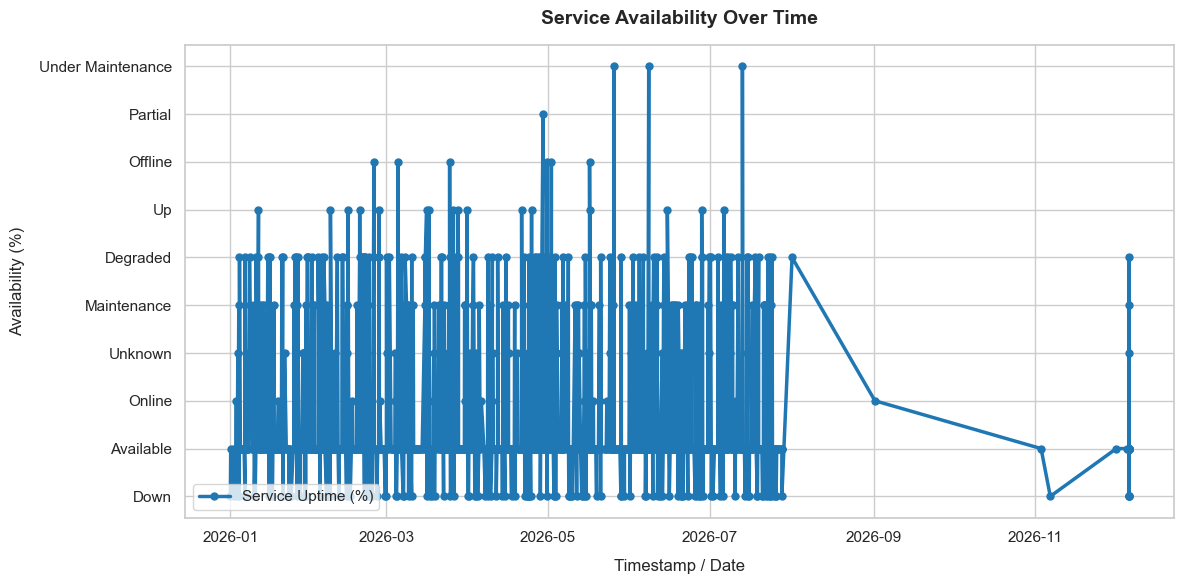

In [163]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))
plt.plot(df['Timestamp'], df['Availability Status'], marker='o', color='#1f77b4', linewidth=2.5, markersize=5, label='Service Uptime (%)')

plt.title('Service Availability Over Time', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Timestamp / Date', fontsize=12, labelpad=10)
plt.ylabel('Availability (%)', fontsize=12, labelpad=10)
plt.xticks(rotation=0)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()

plt.show()

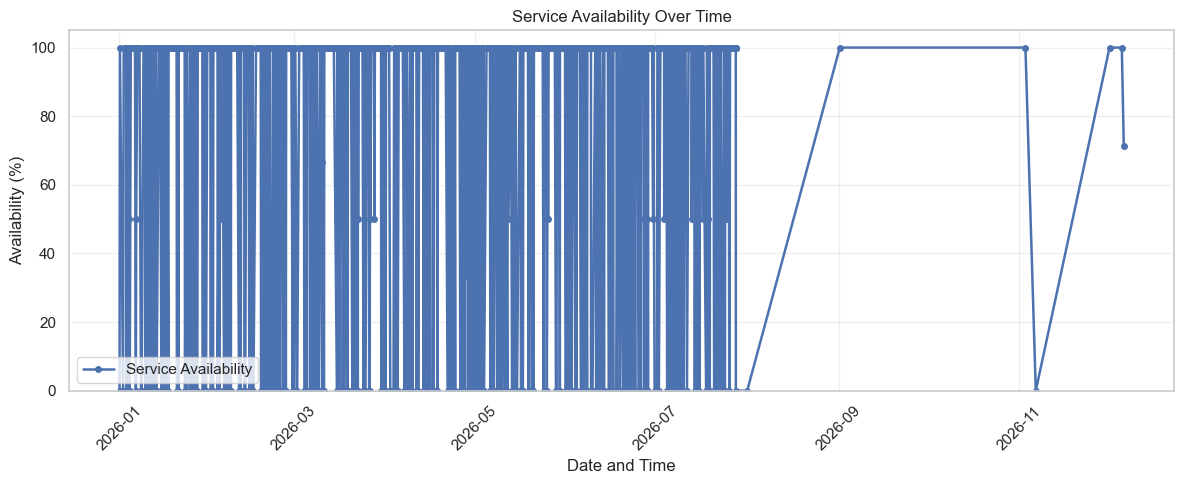

In [164]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert Timestamp into datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')

# Remove missing timestamps
df = df.dropna(subset=['Timestamp'])

# Sort data by time
df = df.sort_values('Timestamp')

# Convert availability status into numeric values
df['Availability'] = df['Availability Status'].map({
    'Available': 1,
    'Online': 1,
    'Up': 1,
    'Down': 0,
    'Offline': 0,
    'Maintenance': 0,
    'Under Maintenance': 0,
    'Degraded': 0,
    'Partial': 0
})

# Calculate availability every 30 minutes
availability = df.set_index('Timestamp')['Availability'].resample('30min').mean() * 100

# Remove missing intervals
availability = availability.dropna()

# Create line chart
plt.figure(figsize=(12, 5))

plt.plot(
    availability.index,
    availability.values,
    marker='o',
    markersize=4,
    linewidth=1.8,
    label='Service Availability'
)

plt.title('Service Availability Over Time')
plt.xlabel('Date and Time')
plt.ylabel('Availability (%)')

plt.ylim(0, 105)
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Create a bar chart comparing total downtime across services.

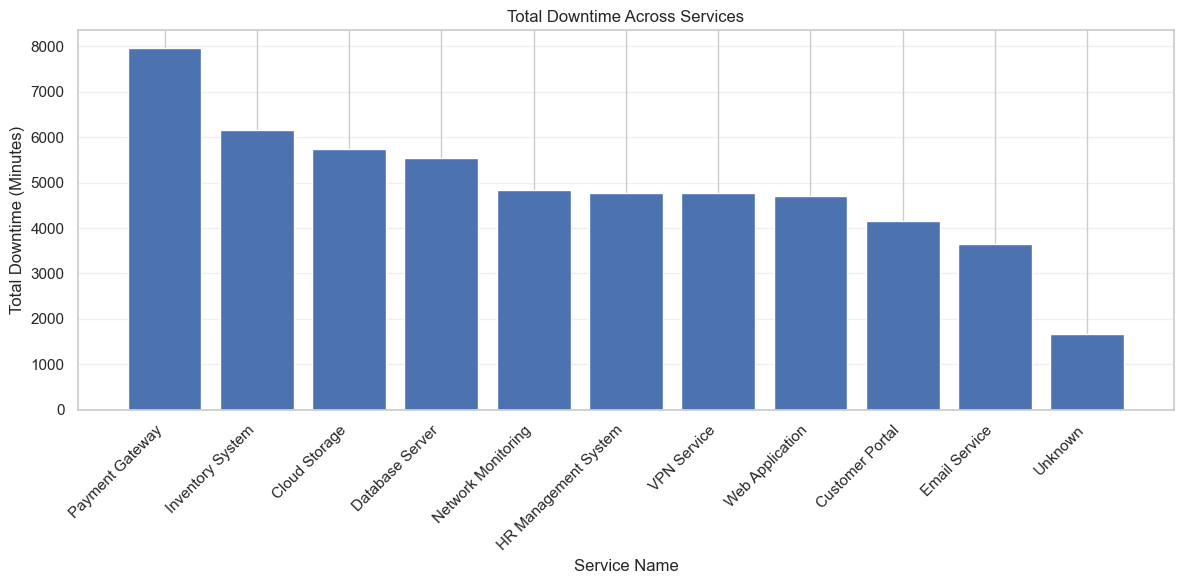

In [165]:
import matplotlib.pyplot as plt

# Calculate total downtime by service
downtime = df.groupby('Service Name')['Downtime Duration'].sum()

# Sort values
downtime = downtime.sort_values(ascending=False)

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(downtime.index, downtime.values)

plt.title('Total Downtime Across Services')
plt.xlabel('Service Name')
plt.ylabel('Total Downtime (Minutes)')

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Create a scatter plot showing response time against downtime duration

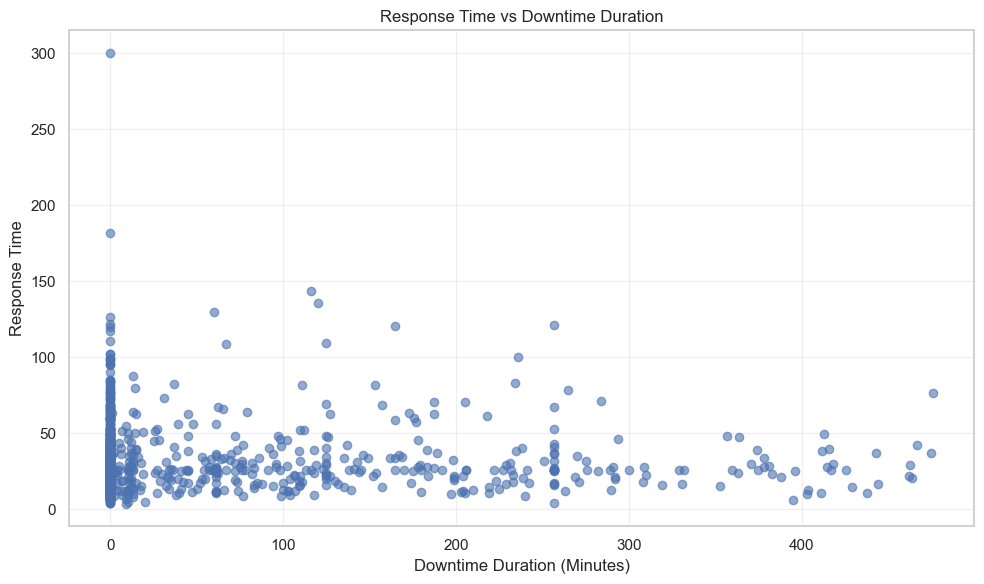

In [166]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert columns into numeric values
df['Response Time'] = pd.to_numeric(df['Response Time'], errors='coerce')
df['Downtime Duration'] = pd.to_numeric(df['Downtime Duration'], errors='coerce')

# Remove missing and invalid values
data = df.dropna(subset=['Response Time', 'Downtime Duration'])

data = data[
    (data['Response Time'] >= 0) &
    (data['Downtime Duration'] >= 0)
]

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    data['Downtime Duration'],
    data['Response Time'],
    alpha=0.6
)

plt.title('Response Time vs Downtime Duration')
plt.xlabel('Downtime Duration (Minutes)')
plt.ylabel('Response Time')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()